# Results 3 — Pair transformations reveal distinct forms of disease-associated dependence

For every synergistic pair the RF received two synthetic encodings, the log-ratio (LR) and the geometric mean (GM). This notebook reports which encoding the classifier relied on.
Inputs: `synthetic_features_<dt>.csv` (selection frequencies, `../M2_loco_crc_pipeline/results/<dt>/`), the stable-pair table from `../R2_classification_performance/final_synthetic_features_table.csv`, and the prepared cohort matrices (for the per-cohort effect sizes in Figure 4).
Outputs: `../manuscript/SuppTable3_transformation_preference.tsv` (pairs selected in ≥ 50 % of folds: LR / GM / both) and `../manuscript/Figure4.{pdf,png}` (nine representative pairs). The LR-only / GM-only / both counts for the stable (≥ 80 %) pairs quoted in the Results text are printed at the end.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load feature files from main_code.ipynb output 
# Process only data types that have been run (for now, only TAXA)

data_types = ['taxa', 'functions', 'combined']
input_dirs = {
    'taxa': '../M2_loco_crc_pipeline/results/taxa',
    'functions': '../M2_loco_crc_pipeline/results/functions',
    'combined': '../M2_loco_crc_pipeline/results/combined'
}

# Load data only for types that exist
data = {}
for data_type in data_types:
    input_dir = input_dirs[data_type]
    raw_file = f'{input_dir}/base_features_{data_type}.csv'
    synth_file = f'{input_dir}/synthetic_features_{data_type}.csv'
    
    if os.path.exists(raw_file) and os.path.exists(synth_file):
        data[data_type] = {
            'raw': pd.read_csv(raw_file),
            'synthetic': pd.read_csv(synth_file)
        }
        print(f"{data_type.capitalize()} - Raw: {len(data[data_type]['raw'])} features, Synthetic: {len(data[data_type]['synthetic'])} features")
    else:
        print(f"{data_type.capitalize()}: Files not found, skipping...")

if not data:
    raise ValueError("No data files found! Please run main_code.ipynb first.")

print(f"\nNote: Using output from main_code.ipynb (consensus pairs in >= 6 of 10 MDFS runs per fold; one RF per fold)")
print(f"Processing: {list(data.keys())}")

Taxa - Raw: 131 features, Synthetic: 861 features
Functions - Raw: 231 features, Synthetic: 1065 features
Combined - Raw: 22 features, Synthetic: 1169 features

Note: Using output from main_code.ipynb (consensus pairs in >= 6 of 10 MDFS runs per fold; one RF per fold)
Processing: ['taxa', 'functions', 'combined']


In [2]:
# Stable pairs (>= 80 % of folds, frequency above both constituents) from R2
SYNTHETIC_THRESHOLD = 80.0
final_results_df = pd.read_csv('../R2_classification_performance/final_synthetic_features_table.csv')
print(f"{len(final_results_df)} stable pairs loaded")
print(final_results_df.groupby('Data Type').size())


211 stable pairs loaded
Data Type
combined     160
functions     17
taxa          34
dtype: int64


In [3]:
# --- Helper functions (effect sizes per cohort for a pair, LR or GM) ---
# Uses `final_results_df` (built above) which already applies:
# - Selection % >= SYNTHETIC_THRESHOLD (default 80%)
# - positive Selection % Gain
# - synthetic Selection % > both component Selection %
#
# This cell validates each selected synthetic pair across cohorts (CRC vs Control):
# - effect size: rank-biserial correlation (rbc) from Mann–Whitney U
# - per-cohort p-values, BH-FDR within each pair
# - compact small-multiples figure (paper-friendly)

from pathlib import Path


def _bh_fdr(pvals):
    p = np.asarray(pvals, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)
    ok = np.isfinite(p)
    if ok.sum() == 0:
        return q

    p_ok = p[ok]
    m = p_ok.size
    order = np.argsort(p_ok)
    ranked = p_ok[order]

    q_ranked = ranked * m / (np.arange(1, m + 1))
    q_ranked = np.minimum.accumulate(q_ranked[::-1])[::-1]
    q_ranked = np.clip(q_ranked, 0, 1)

    q_ok = np.empty_like(p_ok)
    q_ok[order] = q_ranked
    q[ok] = q_ok
    return q


def _cohort_stems_for_data_type(data_type: str):
    base = Path("..") / "M1_data_preparation" / "prepared_data"
    paths = sorted(base.glob(f"X_*_{data_type}.tsv"))
    suffix = f"_{data_type}.tsv"
    out = []
    for p in paths:
        name = p.name
        if not name.startswith("X_") or not name.endswith(suffix):
            continue
        out.append(name[len("X_") : -len(suffix)])
    return out


def load_X_y_for_cohort(cohort_stem: str, data_type: str):
    base = Path("..") / "M1_data_preparation" / "prepared_data"
    X_path = base / f"X_{cohort_stem}_{data_type}.tsv"
    y_path = base / f"y_{cohort_stem}_{data_type}.tsv"

    # Fallback: any y for cohort
    if not y_path.exists():
        cands = sorted(base.glob(f"y_{cohort_stem}_*.tsv"))
        if cands:
            y_path = cands[0]

    if not X_path.exists() or not y_path.exists():
        return None, None

    X = pd.read_csv(X_path, sep="\t", index_col=0)
    y_df = pd.read_csv(y_path, sep="\t", index_col=0)
    if "Study condition" not in y_df.columns:
        return None, None

    # Normalize (relative abundance)
    X = X.div(X.sum(axis=1), axis=0)

    y = y_df["Study condition"].astype(int)

    # Align
    common = X.index.intersection(y.index)
    X = X.loc[common]
    y = y.loc[common]

    return X, y


def find_matching_feature_name(feature_name, available_columns):
    # exact
    if feature_name in available_columns:
        return feature_name

    # functions/pathways: use prefix before ':'
    if isinstance(feature_name, str) and ':' in feature_name:
        pathway_id = feature_name.split(':')[0].strip()
        if pathway_id in available_columns:
            return pathway_id
        for col in available_columns:
            if col.startswith(pathway_id) or col == pathway_id:
                return col

    # case-insensitive
    if isinstance(feature_name, str):
        fl = feature_name.lower()
        for col in available_columns:
            if str(col).lower() == fl:
                return col

    # partial
    if isinstance(feature_name, str):
        for col in available_columns:
            c = str(col)
            if len(feature_name) > 5 and len(c) > 5 and (feature_name in c or c in feature_name):
                return col

    return None


def compute_synthetic_feature_from_X(X: pd.DataFrame, feature1: str, feature2: str, feature_type: str, epsilon: float = 1e-9):
    f1 = find_matching_feature_name(feature1, X.columns)
    f2 = find_matching_feature_name(feature2, X.columns)
    if f1 is None or f2 is None:
        return None

    a = X[f1].to_numpy(dtype=float)
    b = X[f2].to_numpy(dtype=float)

    if feature_type == "LR":
        return np.log((a + epsilon) / (b + epsilon))
    if feature_type == "GM":
        return np.sqrt((a + epsilon) * (b + epsilon))
    return None


def _compute_rbc_and_p(disease_vals: np.ndarray, health_vals: np.ndarray):
    from scipy.stats import mannwhitneyu

    disease_vals = np.asarray(disease_vals, dtype=float)
    health_vals = np.asarray(health_vals, dtype=float)
    disease_vals = disease_vals[np.isfinite(disease_vals)]
    health_vals = health_vals[np.isfinite(health_vals)]

    n_crc = len(disease_vals)
    n_ctrl = len(health_vals)
    if n_crc == 0 or n_ctrl == 0:
        return np.nan, np.nan, n_crc, n_ctrl

    try:
        U, p = mannwhitneyu(disease_vals, health_vals, alternative="two-sided")
    except Exception:
        return np.nan, 1.0, n_crc, n_ctrl

    denom = n_crc * n_ctrl
    rbc = (2 * U / denom - 1) if denom > 0 else np.nan
    return float(rbc), float(p), n_crc, n_ctrl


def _shorten_pwy(s):
    if s is None:
        return "", None
    s = str(s)
    if ":" in s:
        prefix = s.split(":", 1)[0]
        if "PWY" in prefix:
            return prefix, s
    return s, None


def _truncate(s, max_len=44):
    if s is None:
        return ""
    s = str(s)
    return s if len(s) <= max_len else (s[: max_len - 1] + "…")


def compute_pair_table_for_final_row(row, try_types=("LR", "GM")):
    data_type = row["Data Type"]
    f1 = row["Feature1"]
    f2 = row["Feature2"]

    cohorts = _cohort_stems_for_data_type(data_type)

    best = None
    for t in try_types:
        rows = []
        for cohort in cohorts:
            X, y = load_X_y_for_cohort(cohort, data_type)
            if X is None or y is None:
                continue

            synth = compute_synthetic_feature_from_X(X, f1, f2, t)
            if synth is None:
                continue

            disease_mask = (y == 0)
            health_mask = (y == 1)
            dvals = np.asarray(synth)[disease_mask.to_numpy()]
            hvals = np.asarray(synth)[health_mask.to_numpy()]

            rbc, p, n_crc, n_ctrl = _compute_rbc_and_p(dvals, hvals)
            if not np.isfinite(rbc) or not np.isfinite(p) or n_crc == 0 or n_ctrl == 0:
                continue

            rows.append(
                {
                    "cohort": cohort,
                    "cohort_short": str(cohort).replace("Public_study__", "").replace("This_study_", ""),
                    "rbc": rbc,
                    "p": p,
                    "n_crc": n_crc,
                    "n_ctrl": n_ctrl,
                }
            )

        df = pd.DataFrame(rows)
        if len(df) == 0:
            continue

        df["q"] = _bh_fdr(df["p"].values)
        # pick best by most cohorts
        cand = (t, df)
        if best is None or len(df) > len(best[1]):
            best = cand

    if best is None:
        return None, pd.DataFrame()

    t, df = best
    df = df.sort_values("q", ascending=True).reset_index(drop=True)
    return t, df


# ----------------- knobs -----------------
# Choose how many of the FINAL table pairs to plot
# (sorted by Selection % Gain then Selection %)
MAX_PAIRS_TO_PLOT = None  # e.g. 12
N_COLS = 3
FIG_DPI = 300

PANEL_W = 4.35
PANEL_H = 3.05
TITLE_FS = 12
PARAM_FS = 10
TICK_FS = 10
PANEL_LABEL_FS = 14
SUP_FS = 14



In [4]:
# =============================================================================
# Supplementary Table 3: LR vs GM transformation preference for ALL pairs
# =============================================================================
# For every synergistic pair selected in >= 50% of LOCO folds (either as LR
# or GM), report which transformation(s) reached that threshold and the
# maximum selection percentage.
#
# Columns:
#   Data Type, Feature1, Feature2, Types_Present, Num_Types, Max_Selection_Pct

SUPP_THRESHOLD = 50.0  # minimum selection % to include

supp_rows = []
for data_type in data_types:
    synth_df = data[data_type]['synthetic']

    # Parse prefix and pair name
    parsed = []
    for _, r in synth_df.iterrows():
        feat = r['Feature']
        sel = r['Selection %']
        if feat.startswith('LR_'):
            prefix, pair = 'LR', feat[3:]
        elif feat.startswith('GM_'):
            prefix, pair = 'GM', feat[3:]
        else:
            continue
        if '__' not in pair:
            continue
        f1, f2 = pair.split('__', 1)
        parsed.append({
            'data_type': data_type,
            'pair': pair,
            'f1': f1,
            'f2': f2,
            'type': prefix,
            'sel': sel,
        })

    pdf = pd.DataFrame(parsed)
    if len(pdf) == 0:
        continue

    # For each pair, collect types present and max selection %
    for pair_name, grp in pdf.groupby('pair'):
        max_sel = grp['sel'].max()
        if max_sel < SUPP_THRESHOLD:
            continue

        # Only count types that individually reach the threshold
        types_above = sorted(grp.loc[grp['sel'] >= SUPP_THRESHOLD, 'type'].unique().tolist())
        if len(types_above) == 0:
            # Pair max is above threshold but no single type is — use the best type
            types_above = [grp.loc[grp['sel'].idxmax(), 'type']]

        f1 = grp.iloc[0]['f1']
        f2 = grp.iloc[0]['f2']

        supp_rows.append({
            'Data Type': data_type,
            'Feature1': f1,
            'Feature2': f2,
            'Types_Present': types_above,
            'Num_Types': len(types_above),
            'Max_Selection_Pct': max_sel,
        })

supp_table = pd.DataFrame(supp_rows)
supp_table = supp_table.sort_values(['Data Type', 'Max_Selection_Pct'], ascending=[True, False])
supp_table = supp_table.reset_index(drop=True)

# Summary
print("=" * 80)
print(f"SUPPLEMENTARY TABLE 3: Transformation preference (pairs >= {SUPP_THRESHOLD}%)")
print("=" * 80)
print(f"Total pairs: {len(supp_table)}")
print(f"\nBreakdown by data type:")
print(supp_table.groupby('Data Type').size())

# Count transformation preference
n_lr_only = len(supp_table[supp_table['Types_Present'].apply(lambda x: x == ['LR'])])
n_gm_only = len(supp_table[supp_table['Types_Present'].apply(lambda x: x == ['GM'])])
n_both = len(supp_table[supp_table['Num_Types'] == 2])
print(f"\nTransformation preference:")
print(f"  LR only:  {n_lr_only} ({100*n_lr_only/len(supp_table):.1f}%)")
print(f"  GM only:  {n_gm_only} ({100*n_gm_only/len(supp_table):.1f}%)")
print(f"  Both:     {n_both} ({100*n_both/len(supp_table):.1f}%)")

# Save
supp_outfile = '../manuscript/SuppTable3_transformation_preference.tsv'
supp_table.to_csv(supp_outfile, sep='\t', index=False)
print(f"\nSaved to: {supp_outfile}")

# Show top rows
print(f"\nTop 20 pairs by Max_Selection_Pct:")
print(supp_table.head(20).to_string(index=False))

SUPPLEMENTARY TABLE 3: Transformation preference (pairs >= 50.0%)
Total pairs: 746

Breakdown by data type:
Data Type
combined     360
functions    130
taxa         256
dtype: int64

Transformation preference:
  LR only:  220 (29.5%)
  GM only:  289 (38.7%)
  Both:     237 (31.8%)

Saved to: ../manuscript/SuppTable3_transformation_preference.tsv

Top 20 pairs by Max_Selection_Pct:
Data Type                                                   Feature1                                Feature2 Types_Present  Num_Types  Max_Selection_Pct
 combined                                    Anaerococcus_obesiensis                  Dialister_pneumosintes      [GM, LR]          2              100.0
 combined                                    Anaerococcus_obesiensis                 Fusobacterium_nucleatum      [GM, LR]          2              100.0
 combined                                    Anaerococcus_obesiensis                     Gemella_morbillorum      [GM, LR]          2              100.0
 com

201 stable pairs scored (figure4_candidates.tsv). Selected for Figure 4:
data_type                                                                                                                                       feature_pair  selection_pct types_ge_50pct  median_abs_r_LR  median_abs_r_GM
 combined                                                                                                Peptostreptococcus_stomatis__Roseburia_intestinalis        100.000        LR-only            0.486            0.051
 combined                                                                                                     Dialister_pneumosintes__Roseburia_intestinalis         92.857        LR-only            0.465            0.080
 combined                                                                                                           Parvimonas_micra__Roseburia_intestinalis         92.857        LR-only            0.401            0.103
     taxa                                  

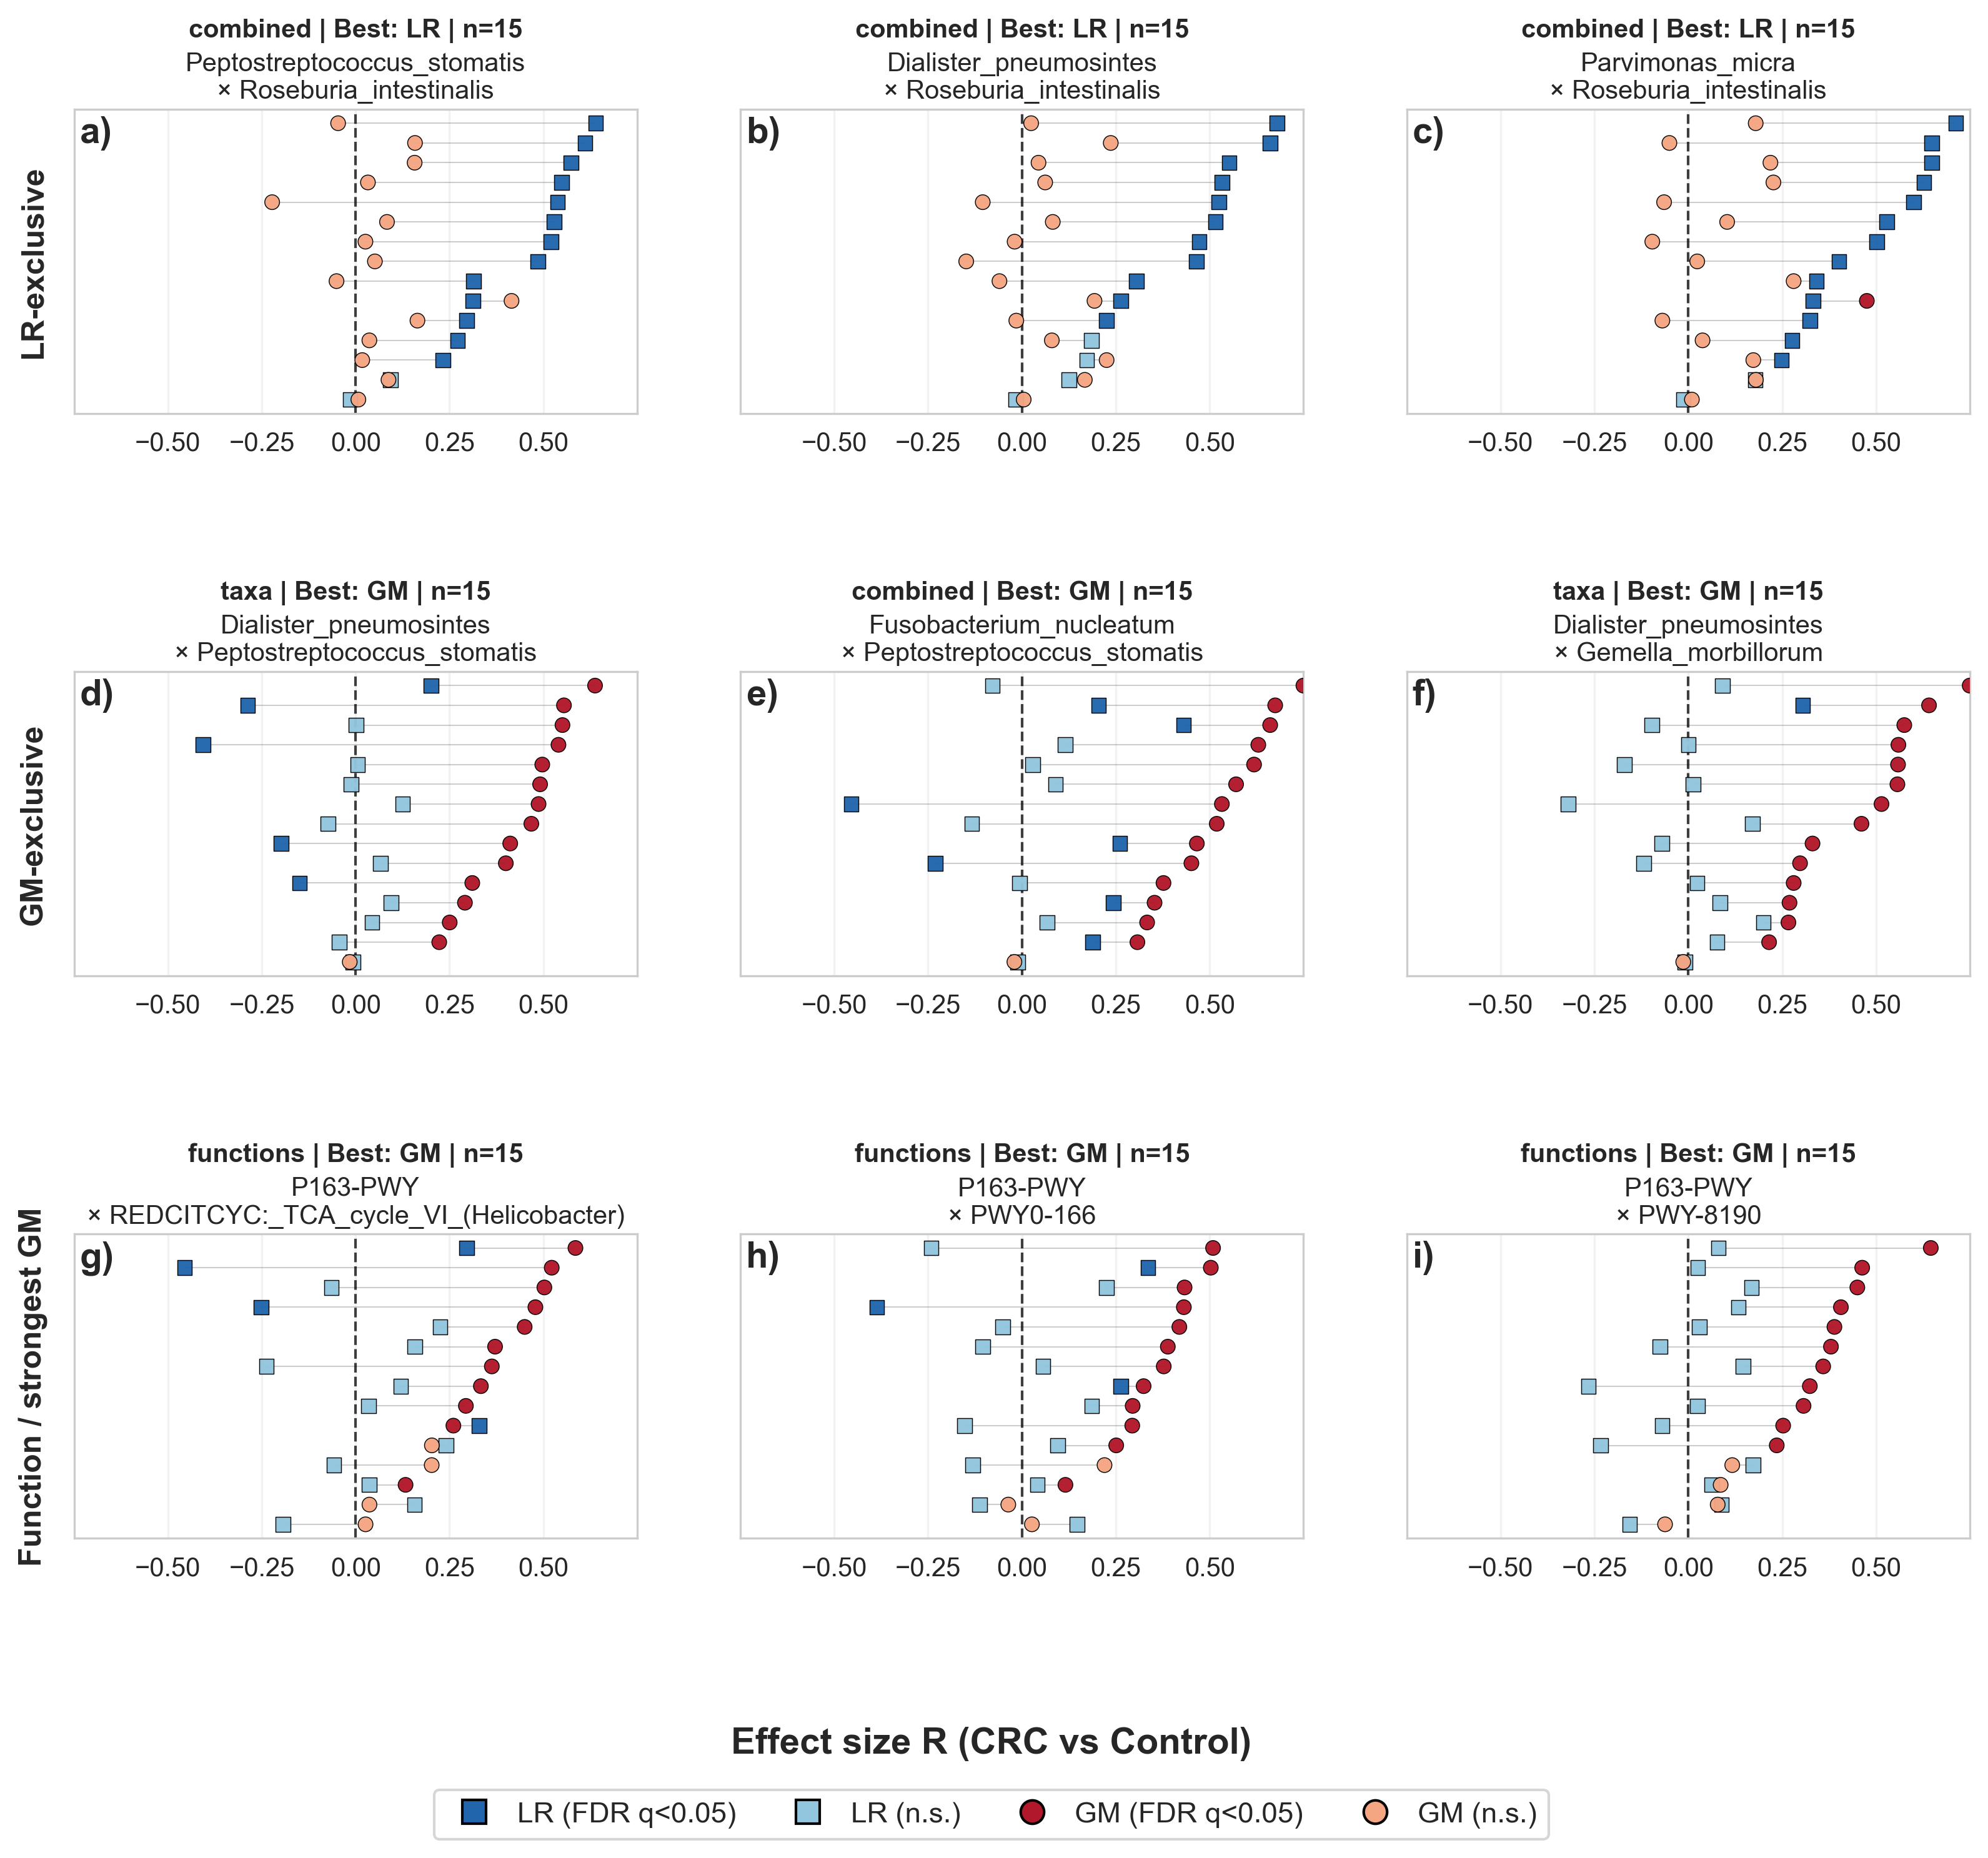

Legend:
  square = LR, circle = GM
  dark = FDR q<0.05 within pair, light = not significant

FIGURE 4 SUMMARY
All 746 pairs (>= 50.0%): LR-only=220, GM-only=289, both=237
Stable pairs (>= 80%): LR-only=92, GM-only=116, both=151

Caption (selected 9 pairs):
  a) combined | LR | LR |r|=0.486  GM |r|=0.051 | Peptostreptococcus_stomatis × Roseburia_intestinalis
  b) combined | LR | LR |r|=0.465  GM |r|=0.080 | Dialister_pneumosintes × Roseburia_intestinalis
  c) combined | LR | LR |r|=0.401  GM |r|=0.103 | Parvimonas_micra × Roseburia_intestinalis
  d) taxa | GM | LR |r|=0.073  GM |r|=0.468 | Dialister_pneumosintes × Peptostreptococcus_stomatis
  e) combined | GM | LR |r|=0.133  GM |r|=0.519 | Fusobacterium_nucleatum × Peptostreptococcus_stomatis
  f) taxa | GM | LR |r|=0.091  GM |r|=0.461 | Dialister_pneumosintes × Gemella_morbillorum
  g) functions | GM | LR |r|=0.193  GM |r|=0.334 | P163-PWY × REDCITCYC:_TCA_cycle_VI_(Heli…
  h) functions | GM | LR |r|=0.147  GM |r|=0.324 | P163-PWY × P

In [5]:
# =============================================================================
# Figure 4: LR vs GM transformation preference — 3x3 representative pairs
# =============================================================================

# ---- Automatic choice of the nine pairs ----
# Candidates = the stable pairs of R2 (>= 80 % of folds, above both constituents). Their transformation
# preference comes from supp_table (which encodings reached >= 50 % selection). For every candidate the
# per-cohort effect sizes of BOTH encodings are computed and the pairs with the largest contrast are shown:
#   row 1: LR-exclusive pairs (taxa/combined) with the largest median |r_LR| - |r_GM|
#   row 2: GM-exclusive pairs (taxa/combined) with the largest median |r_GM| - |r_LR|
#   row 3: functional pairs with the strongest GM effect (GM-exclusive preferred)
import functools
load_X_y_for_cohort = functools.lru_cache(maxsize=None)(load_X_y_for_cohort)   # cohort matrices are re-used ~400x

_tmap = {}
for _, r in supp_table.iterrows():
    _tmap[(r['Data Type'], tuple(sorted((r['Feature1'], r['Feature2']))))] = (list(r['Types_Present']), r['Max_Selection_Pct'])


def _lr_gm_medians(data_type, f1, f2):
    med = {}
    for ft in ('LR', 'GM'):
        vals = []
        for cohort in _cohort_stems_for_data_type(data_type):
            X, y = load_X_y_for_cohort(cohort, data_type)
            if X is None:
                continue
            synth = compute_synthetic_feature_from_X(X, f1, f2, ft)
            if synth is None:
                continue
            rbc, p, n1, n0 = _compute_rbc_and_p(np.asarray(synth)[(y == 0).to_numpy()], np.asarray(synth)[(y == 1).to_numpy()])
            if np.isfinite(rbc):
                vals.append(abs(rbc))
        med[ft] = float(np.median(vals)) if vals else np.nan
    return med['LR'], med['GM']


_cands = []
for _, r in final_results_df.iterrows():
    types, maxsel = _tmap.get((r['Data Type'], tuple(sorted((r['Feature1'], r['Feature2'])))), ([], np.nan))
    cat = 'LR-only' if types == ['LR'] else 'GM-only' if types == ['GM'] else 'both' if len(types) == 2 else 'n/a'
    lr_m, gm_m = _lr_gm_medians(r['Data Type'], r['Feature1'], r['Feature2'])
    _cands.append({'data_type': r['Data Type'], 'feature_pair': r['Feature'], 'f1': r['Feature1'], 'f2': r['Feature2'],
                   'selection_pct': r['Selection %'], 'types_ge_50pct': cat, 'median_abs_r_LR': lr_m, 'median_abs_r_GM': gm_m,
                   'contrast_LR_minus_GM': lr_m - gm_m})
cands = pd.DataFrame(_cands)
cands.to_csv('figure4_candidates.tsv', sep='\t', index=False)
# a pair found in several data types is shown once (the data type with the higher selection %)
cands['pair_key'] = [tuple(sorted((a, b))) for a, b in zip(cands.f1, cands.f2)]
cands = cands.sort_values('selection_pct', ascending=False).drop_duplicates('pair_key').sort_index()

_tx = cands[cands.data_type.isin(['taxa', 'combined'])]
row1 = _tx[_tx.types_ge_50pct == 'LR-only'].sort_values('contrast_LR_minus_GM', ascending=False).head(3)
row2 = _tx[_tx.types_ge_50pct == 'GM-only'].sort_values('contrast_LR_minus_GM', ascending=True).head(3)
_fn = cands[cands.data_type == 'functions'].copy()
_fn['pref_gm'] = (_fn.types_ge_50pct == 'GM-only').astype(int)
row3 = _fn.sort_values(['pref_gm', 'median_abs_r_GM'], ascending=[False, False]).head(3)
SELECTED_PAIRS = [(r.data_type, r.feature_pair) for r in pd.concat([row1, row2, row3]).itertuples()]

print(f"{len(cands)} stable pairs scored (figure4_candidates.tsv). Selected for Figure 4:")
print(pd.concat([row1, row2, row3])[['data_type', 'feature_pair', 'selection_pct', 'types_ge_50pct', 'median_abs_r_LR', 'median_abs_r_GM']].round(3).to_string(index=False))

ROW_LABELS = ['LR-exclusive', 'GM-exclusive', 'Function / strongest GM']

# ---- compute both LR and GM per cohort for each pair ----
fig4_panels = []
fig4_all_rbc = []

for data_type, feature_pair in SELECTED_PAIRS:
    sel_row = final_results_df[
        (final_results_df['Data Type'] == data_type) &
        (final_results_df['Feature'] == feature_pair)
    ]
    if len(sel_row) > 0:
        f1 = sel_row.iloc[0]['Feature1']
        f2 = sel_row.iloc[0]['Feature2']
    else:
        parts = feature_pair.split('__', 1)
        f1, f2 = (parts[0], parts[1]) if len(parts) == 2 else (feature_pair, '')

    cohorts = _cohort_stems_for_data_type(data_type)

    type_results = {}
    for ft in ('LR', 'GM'):
        rows = []
        for cohort in cohorts:
            X, y = load_X_y_for_cohort(cohort, data_type)
            if X is None or y is None:
                continue
            synth = compute_synthetic_feature_from_X(X, f1, f2, ft)
            if synth is None:
                continue
            disease_mask = (y == 0).to_numpy()
            health_mask = (y == 1).to_numpy()
            rbc, p, n_crc, n_ctrl = _compute_rbc_and_p(
                np.asarray(synth)[disease_mask],
                np.asarray(synth)[health_mask],
            )
            if np.isfinite(rbc) and np.isfinite(p):
                rows.append({
                    'cohort': cohort,
                    'cohort_short': cohort.replace('Public_study__', '').replace('This_study_', ''),
                    'rbc': rbc, 'p': p,
                })
        df = pd.DataFrame(rows)
        if len(df) > 0:
            df['q'] = _bh_fdr(df['p'].values)
        type_results[ft] = df

    lr_df = type_results['LR'].set_index('cohort_short') if len(type_results['LR']) > 0 else pd.DataFrame()
    gm_df = type_results['GM'].set_index('cohort_short') if len(type_results['GM']) > 0 else pd.DataFrame()

    common = sorted(set(lr_df.index) & set(gm_df.index)) if len(lr_df) > 0 and len(gm_df) > 0 else []

    lr_rbc = lr_df.loc[common, 'rbc'].values if common else np.array([])
    gm_rbc = gm_df.loc[common, 'rbc'].values if common else np.array([])
    lr_q = lr_df.loc[common, 'q'].values if common else np.array([])
    gm_q = gm_df.loc[common, 'q'].values if common else np.array([])

    lr_med = np.median(np.abs(lr_rbc)) if len(lr_rbc) > 0 else 0
    gm_med = np.median(np.abs(gm_rbc)) if len(gm_rbc) > 0 else 0
    dominant = 'LR' if lr_med > gm_med else 'GM'
    dom_rbc = lr_rbc if dominant == 'LR' else gm_rbc
    sort_idx = np.argsort(-np.abs(dom_rbc)) if len(dom_rbc) > 0 else np.array([], dtype=int)

    fig4_all_rbc.extend(lr_rbc.tolist())
    fig4_all_rbc.extend(gm_rbc.tolist())

    fig4_panels.append({
        'data_type': data_type, 'f1': f1, 'f2': f2,
        'cohort_labels': [common[i] for i in sort_idx],
        'lr_rbc': lr_rbc[sort_idx], 'gm_rbc': gm_rbc[sort_idx],
        'lr_q': lr_q[sort_idx], 'gm_q': gm_q[sort_idx],
        'dominant': dominant, 'lr_med': lr_med, 'gm_med': gm_med,
    })

# ---- plot 3x3 ----
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

N_COLS_F4 = 3
N_ROWS_F4 = 3
xlim4 = max(0.25, float(np.nanmax(np.abs(fig4_all_rbc)))) if fig4_all_rbc else 0.5
xlim4 = min(1.0, xlim4)

fig = plt.figure(figsize=(PANEL_W * N_COLS_F4, 3.3 * N_ROWS_F4), dpi=FIG_DPI)
gs4 = GridSpec(N_ROWS_F4, N_COLS_F4 * 2, figure=fig, wspace=0.45, hspace=0.85)

panel_letters = 'abcdefghi'
axes_grid = {}

for idx, pdata in enumerate(fig4_panels):
    rr = idx // N_COLS_F4
    cc = idx % N_COLS_F4
    ax = fig.add_subplot(gs4[rr, cc * 2 : cc * 2 + 2])
    axes_grid[(rr, cc)] = ax

    cohort_labels = pdata['cohort_labels']
    n_c = len(cohort_labels)
    if n_c == 0:
        ax.text(0.5, 0.5, "No data", ha="center", va="center",
                transform=ax.transAxes, fontsize=TITLE_FS)
        ax.set_axis_off()
        continue

    y = np.arange(n_c)

    lr_colors = np.where(pdata['lr_q'] < 0.05, '#2166ac', '#92c5de')
    gm_colors = np.where(pdata['gm_q'] < 0.05, '#b2182b', '#f4a582')

    ax.scatter(pdata['lr_rbc'], y, c=lr_colors, s=32, alpha=0.97,
               edgecolors='black', linewidth=0.35, marker='s', zorder=3)
    ax.scatter(pdata['gm_rbc'], y, c=gm_colors, s=32, alpha=0.97,
               edgecolors='black', linewidth=0.35, marker='o', zorder=3)

    for j in range(n_c):
        ax.plot([pdata['lr_rbc'][j], pdata['gm_rbc'][j]], [y[j], y[j]],
                color='gray', linewidth=0.5, alpha=0.4, zorder=2)

    ax.axvline(0, color='black', linestyle='--', linewidth=1.0, alpha=0.75)

    if n_c <= 8:
        ax.set_yticks(y)
        ax.set_yticklabels(cohort_labels, fontsize=TICK_FS)
    else:
        ax.set_yticks([])

    ax.invert_yaxis()
    ax.set_xlim(-xlim4, xlim4)
    ax.grid(axis='x', alpha=0.25)
    ax.tick_params(axis='x', labelsize=TICK_FS)

    label = f"{panel_letters[idx]})"
    ax.text(0.01, 0.98, label, transform=ax.transAxes, ha='left', va='top',
            fontsize=PANEL_LABEL_FS, fontweight='bold')

    # Subtitle: bold first line, normal-weight feature names on lines 2-3
    f1_short, _ = _shorten_pwy(pdata['f1'])
    f2_short, _ = _shorten_pwy(pdata['f2'])
    f1_disp = _truncate(f1_short, 38)
    f2_disp = _truncate(f2_short, 38)

    # Line 1: bold metadata
    ax.text(0.5, 1.22,
            f"{pdata['data_type']} | Best: {pdata['dominant']} | n={n_c}",
            transform=ax.transAxes, ha='center', va='bottom',
            fontsize=PARAM_FS, fontweight='bold')
    # Lines 2-3: normal weight feature names
    ax.text(0.5, 1.02,
            f"{f1_disp}\n\u00d7 {f2_disp}",
            transform=ax.transAxes, ha='center', va='bottom',
            fontsize=PARAM_FS, fontweight='normal', linespacing=1.2)

# Row labels on first-column axes
for row_idx, label in enumerate(ROW_LABELS):
    if (row_idx, 0) in axes_grid:
        axes_grid[(row_idx, 0)].set_ylabel(label, fontsize=12, fontweight='bold', labelpad=10)

# X-axis label — pushed down slightly to open gap above legend
fig.supxlabel("Effect size R (CRC vs Control)",
              fontsize=SUP_FS, fontweight='bold', y=-0.01)

# Legend — lower to create gap from bottom row
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#2166ac',
           markeredgecolor='black', markersize=9, label='LR (FDR q<0.05)'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#92c5de',
           markeredgecolor='black', markersize=9, label='LR (n.s.)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#b2182b',
           markeredgecolor='black', markersize=9, label='GM (FDR q<0.05)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#f4a582',
           markeredgecolor='black', markersize=9, label='GM (n.s.)'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=4, frameon=True,
           fontsize=11, bbox_to_anchor=(0.5, -0.06),
           handletextpad=0.5, columnspacing=1.5)

plt.savefig('../manuscript/Figure4.pdf', dpi=300, bbox_inches='tight')
plt.savefig('../manuscript/Figure4.png', dpi=300, bbox_inches='tight')
plt.show()

print("Legend:")
print("  square = LR, circle = GM")
print("  dark = FDR q<0.05 within pair, light = not significant")

# ---- Summary ----
print("\n" + "=" * 80)
print("FIGURE 4 SUMMARY")
print("=" * 80)
n_lr_only = len(supp_table[supp_table['Types_Present'].apply(lambda x: x == ['LR'])])
n_gm_only = len(supp_table[supp_table['Types_Present'].apply(lambda x: x == ['GM'])])
n_both = len(supp_table[supp_table['Num_Types'] == 2])
print(f"All {len(supp_table)} pairs (>= {SUPP_THRESHOLD}%): LR-only={n_lr_only}, GM-only={n_gm_only}, both={n_both}")

supp_stable = supp_table[supp_table['Max_Selection_Pct'] >= 80.0]
n_lr_s = len(supp_stable[supp_stable['Types_Present'].apply(lambda x: x == ['LR'])])
n_gm_s = len(supp_stable[supp_stable['Types_Present'].apply(lambda x: x == ['GM'])])
n_both_s = len(supp_stable[supp_stable['Num_Types'] == 2])
print(f"Stable pairs (>= 80%): LR-only={n_lr_s}, GM-only={n_gm_s}, both={n_both_s}")

print("\nCaption (selected 9 pairs):")
for i, pdata in enumerate(fig4_panels):
    f1s, _ = _shorten_pwy(pdata['f1'])
    f2s, _ = _shorten_pwy(pdata['f2'])
    print(f"  {panel_letters[i]}) {pdata['data_type']} | {pdata['dominant']} | "
          f"LR |r|={pdata['lr_med']:.3f}  GM |r|={pdata['gm_med']:.3f} | "
          f"{_truncate(f1s, 30)} \u00d7 {_truncate(f2s, 30)}")
print("=" * 80)
